# IaCGen-MAS without the Retriever with Claude-Opus-5.5 against IaCGen-MAS with the same model, beside the DeepSeek-V4-Flash pair (CloudFormation)

## Setup

In [1]:
import sys, os, re, json, csv, glob, warnings, collections
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
csv.field_size_limit(sys.maxsize)
sys.path.insert(0, "audit")
import repair_loop as rl

FINAL = Path("../results"); DATA = Path("../data"); RES = Path("result/final")
RUNS = os.environ.get("IACGOD_RUNS", "../runs")
CACHE = FINAL / "_analysis_cache"; CACHE.mkdir(exist_ok=True)
FIG = Path("plots/no_retrieval_opus"); FIG.mkdir(parents=True, exist_ok=True)
OUT = RES
plt.style.use("ggplot"); sns.set_palette("muted")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 100, "display.max_rows", 200)

EXPS = {("Claude-Opus-5.5", "IaCGen-MAS"): "CFN_RealAWS_Opus55", ("Claude-Opus-5.5", "Without Retriever"): "CFN_RealAWS_NoRetrieval_Opus55",
        ("DeepSeek-V4-Flash", "IaCGen-MAS"): "CFN_RealAWS_DSV4F", ("DeepSeek-V4-Flash", "Without Retriever"): "CFN_RealAWS_NoRetrieval_DSV4Flash"}
MODELS = ["Claude-Opus-5.5", "DeepSeek-V4-Flash"]; ARMS = ["IaCGen-MAS", "Without Retriever"]
LV = [1, 2, 3, 4, 5]
CLASSES = ["syntax", "schema", "security", "deploy"]

def mcnemar(a, b):
    a = np.asarray(a, bool); b = np.asarray(b, bool)
    oa, ob = int((a & ~b).sum()), int((~a & b).sum())
    return oa, ob, (stats.binomtest(oa, oa + ob, 0.5).pvalue if oa + ob else 1.0)

## Load the results

In [2]:
bench = pd.read_csv(DATA / "cfn_eval_benchmark_real_aws.csv").drop_duplicates("row_number").set_index("row_number")
dcol = "difficulty" if "difficulty" in bench else "difficulty_level"
USECOLS = {"row_number", "run_id", "validity", "iterations_used", "llm_calls_total", "token_all_tokens", "duration_seconds", "deploy_error_message",
           "val_stage_yaml_passed", "val_stage_cfn-lint_passed", "val_stage_trivy_passed", "deploy_passed", "latest_error_cfn-lint", "latest_error_trivy"}
frames = []
for (model, arm), e in EXPS.items():
    r = pd.read_csv(FINAL / e / "results_final.csv", engine="python", usecols=lambda c: c in USECOLS).drop_duplicates("row_number")
    r["model"], r["arm"], r["exp"] = model, arm, e
    r["difficulty"] = r.row_number.map(bench[dcol]).astype(int)
    r["passed"] = r.validity.eq("valid_pass") & (r.iterations_used <= 15)
    frames.append(r)
runs = pd.concat(frames, ignore_index=True)
runs.groupby(["model", "arm"]).agg(rows=("row_number", "size"), passed=("passed", "sum"), invalid=("validity", lambda s: int(s.astype(str).str.startswith("invalid").sum())))

rows  passed  invalid
model             arm                                     
Claude-Opus-5.5   IaCGen-MAS          250     246        0
                  Without Retriever   250     244        0
DeepSeek-V4-Flash IaCGen-MAS          250     247        1
                  Without Retriever   250     234        6

## Pass rate, first attempt and iterations

In [3]:
rows = []
for (model, arm), g in runs.groupby(["model", "arm"], sort=False):
    p = g.passed
    rows.append(dict(model=model, arm=arm, rows=len(g), passed=int(p.sum()), pass_pct=round(100 * p.mean(), 1), first_attempt=int((p & (g.iterations_used == 1)).sum()),
                     first_attempt_pct=round(100 * (p & (g.iterations_used == 1)).mean(), 1), iters_mean_passed=round(g.loc[p, "iterations_used"].mean(), 2),
                     iters_median_passed=g.loc[p, "iterations_used"].median(), repaired_runs=int((g.iterations_used > 1).sum()),
                     **{f"L{k}": round(100 * p[g.difficulty == k].mean(), 1) for k in LV}))
PASS = pd.DataFrame(rows)
PASS

,model,arm,rows,passed,pass_pct,first_attempt,first_attempt_pct,iters_mean_passed,iters_median_passed,repaired_runs,L1,L2,L3,L4,L5
0,Claude-Opus-5.5,IaCGen-MAS,250,246,98.4,154,61.6,1.55,1.0,96,96.0,100.0,98.0,100.0,98.0
1,Claude-Opus-5.5,Without Retriever,250,244,97.6,159,63.6,1.55,1.0,91,96.0,100.0,94.0,100.0,98.0
2,DeepSeek-V4-Flash,IaCGen-MAS,250,247,98.8,48,19.2,3.71,3.0,202,96.0,100.0,100.0,100.0,98.0
3,DeepSeek-V4-Flash,Without Retriever,250,234,93.6,56,22.4,3.37,3.0,194,90.0,94.0,98.0,90.0,96.0


## Paired comparison

In [4]:
R = {(m, a): runs[(runs.model == m) & (runs.arm == a)].set_index("row_number") for m in MODELS for a in ARMS}
rows = []
for m in MODELS:
    a, b = R[(m, "IaCGen-MAS")], R[(m, "Without Retriever")]
    idx = a.index.intersection(b.index)
    oa, ob, p = mcnemar(a.loc[idx, "passed"], b.loc[idx, "passed"])
    both = a.loc[idx, "passed"] & b.loc[idx, "passed"]
    ia, ib = a.loc[idx][both].iterations_used, b.loc[idx][both].iterations_used
    rows.append(dict(model=m, rows=len(idx), mas=int(a.loc[idx, "passed"].sum()), without_retriever=int(b.loc[idx, "passed"].sum()), only_mas=oa, only_without=ob, p=p,
                     both_passed=int(both.sum()), iters_mas=round(ia.mean(), 2), iters_without=round(ib.mean(), 2), fewer_with_mas=int((ia < ib).sum()), fewer_without=int((ib < ia).sum()),
                     wilcoxon_p=stats.wilcoxon(ia, ib).pvalue if (ia != ib).any() else 1.0))
PAIRED = pd.DataFrame(rows)
DISC = pd.concat([pd.DataFrame({"model": m, "row_number": i, "difficulty": R[(m, "IaCGen-MAS")].loc[i, "difficulty"],
                                "passes_with": "IaCGen-MAS" if R[(m, "IaCGen-MAS")].loc[i, "passed"] else "Without Retriever"}, index=[0])
                  for m in MODELS for i in R[(m, "IaCGen-MAS")].index.intersection(R[(m, "Without Retriever")].index)
                  if R[(m, "IaCGen-MAS")].loc[i, "passed"] != R[(m, "Without Retriever")].loc[i, "passed"]], ignore_index=True)
display(PAIRED); DISC

,model,rows,mas,without_retriever,only_mas,only_without,p,both_passed,iters_mas,iters_without,fewer_with_mas,fewer_without,wilcoxon_p
0,Claude-Opus-5.5,250,246,244,4,2,0.687500,242,1.55,1.55,30,32,0.401674
1,DeepSeek-V4-Flash,250,247,234,14,1,0.000977,233,3.50,3.36,74,82,0.467841


,model,row_number,difficulty,passes_with
0,Claude-Opus-5.5,1,1,Without Retriever
1,Claude-Opus-5.5,34,1,IaCGen-MAS
2,Claude-Opus-5.5,77,3,IaCGen-MAS
3,Claude-Opus-5.5,163,5,IaCGen-MAS
4,Claude-Opus-5.5,174,5,Without Retriever
5,Claude-Opus-5.5,230,3,IaCGen-MAS
6,DeepSeek-V4-Flash,20,1,IaCGen-MAS
7,DeepSeek-V4-Flash,26,1,IaCGen-MAS
8,DeepSeek-V4-Flash,34,1,IaCGen-MAS
9,DeepSeek-V4-Flash,37,2,IaCGen-MAS


## passItr@n

n,1,2,3,5,10,15
"Claude-Opus-5.5, IaCGen-MAS",61.6,88.8,94.0,97.6,98.4,98.4
"Claude-Opus-5.5, Without Retriever",63.6,88.0,93.2,96.0,97.2,97.6
"DeepSeek-V4-Flash, IaCGen-MAS",19.2,47.6,62.4,80.0,93.2,98.8
"DeepSeek-V4-Flash, Without Retriever",22.4,45.2,62.0,78.8,90.4,93.6


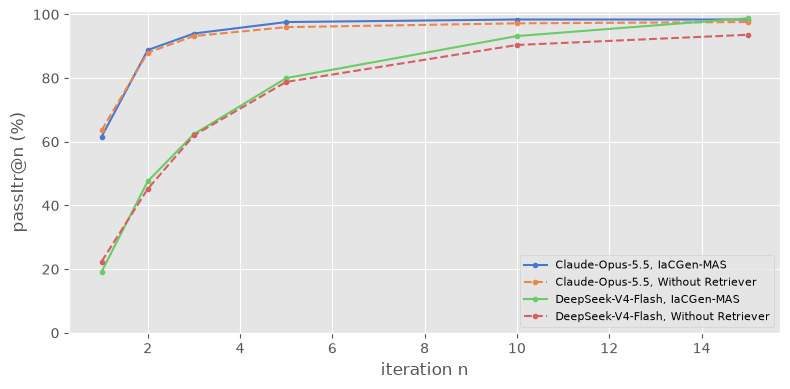

In [5]:
N = [1, 2, 3, 5, 10, 15]
CURVE = pd.DataFrame({f"{m}, {a}": [round(100 * (g.passed & (g.iterations_used <= n)).mean(), 1) for n in N] for (m, a), g in runs.groupby(["model", "arm"], sort=False)}, index=pd.Index(N, name="n")).T
display(CURVE)
fig, ax = plt.subplots(figsize=(8, 4))
for c, x in CURVE.iterrows():
    ax.plot(N, x.values, marker="o", ms=3, label=c, ls="-" if "MAS" in c else "--")
ax.set_xlabel("iteration n"); ax.set_ylabel("passItr@n (%)"); ax.set_ylim(0, 101); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "passitr_curve.png", dpi=160); plt.show()

## Effort

In [6]:
EFFORT = runs.groupby(["model", "arm"], sort=False).agg(llm_calls=("llm_calls_total", "mean"), ktokens=("token_all_tokens", lambda s: s.mean() / 1000),
                                                        ktokens_median=("token_all_tokens", lambda s: s.median() / 1000), minutes=("duration_seconds", lambda s: s.mean() / 60)).round(2).reset_index()
EFFORT

,model,arm,llm_calls,ktokens,ktokens_median,minutes
0,Claude-Opus-5.5,IaCGen-MAS,4.02,19.02,11.11,6.92
1,Claude-Opus-5.5,Without Retriever,3.75,20.03,10.97,6.86
2,DeepSeek-V4-Flash,IaCGen-MAS,10.15,151.11,39.51,21.18
3,DeepSeek-V4-Flash,Without Retriever,8.23,361.88,56.54,24.40


## LLM calls per agent

In [7]:
p = CACHE / "agent_calls_noretrieval_opus.csv"
if Path(RUNS).exists():
    idx = rl.index_runs(RUNS); rows = []
    for (m, a), e in EXPS.items():
        if m != "Claude-Opus-5.5":
            continue
        for rid in runs.loc[runs.exp == e, "run_id"].dropna().astype(str):
            f = Path(idx.get(rid, "")) / "llm_calls.jsonl"
            c = collections.Counter(json.loads(l).get("agent") for l in open(f)) if f.exists() else collections.Counter()
            rows.append(dict(model=m, arm=a, run_id=rid, **c))
    pd.DataFrame(rows).fillna(0).to_csv(p, index=False)
AGENTS = pd.read_csv(p).groupby(["model", "arm"]).sum(numeric_only=True).reset_index()
AGENTS

,model,arm,planner,engineer,retriever,remediator
0,Claude-Opus-5.5,IaCGen-MAS,250,442,120.0,192.0
1,Claude-Opus-5.5,Without Retriever,250,469,0.0,219.0


## Failing checks

In [8]:
INDEX = None
def load_iters(e):
    global INDEX
    p = CACHE / f"iters_{e}.pkl"; p_ids = CACHE / f"iters_{e}.run_ids.json"
    rids = sorted(runs.loc[runs.exp == e, "run_id"].dropna().astype(str).unique())
    if p.exists() and p_ids.exists() and json.load(open(p_ids)) == rids:
        return pd.read_pickle(p)
    if INDEX is None:
        INDEX = rl.index_runs(RUNS)
    df = rl.build_iteration_table(runs.loc[runs.exp == e, ["run_id", "row_number"]].dropna(), RUNS, "CFN", index=INDEX, blocking=rl.BLOCKING_DEFAULT)
    df.to_pickle(p); json.dump(rids, open(p_ids, "w"))
    return df
parts = []
for (m, a), e in EXPS.items():
    d = load_iters(e); d = d[d.run_id.astype(str).isin(runs.loc[runs.exp == e, "run_id"].astype(str))]
    d["model"], d["arm"] = m, a; parts.append(d)
iters = pd.concat(parts, ignore_index=True)
iters = iters[iters.iteration <= 15]
for c in CLASSES:
    iters[f"{c}_ran"] = iters[f"{c}_ran"].fillna(False).astype(bool)
    iters[f"{c}_ok"] = iters[f"{c}_ok"].fillna(True).astype(bool)
fail = iters[~iters.validation_passed.astype(bool)]
FAILING = pd.concat({c: fail.groupby(["model", "arm"])[[f"{c}_ran", f"{c}_ok"]].apply(lambda g: int((g.iloc[:, 0] & ~g.iloc[:, 1]).sum())) for c in CLASSES}, axis=1)
FAILING.insert(0, "failing_iterations", fail.groupby(["model", "arm"]).size())
FAILING

failing_iterations  syntax  schema  security  deploy
model             arm                                                                    
Claude-Opus-5.5   IaCGen-MAS                        196      21      34        73      89
                  Without Retriever                 225      15      30        82     113
DeepSeek-V4-Flash IaCGen-MAS                        714      65     225        97     379
                  Without Retriever                 795      37     245        88     457

## Repair turns

In [9]:
tt = []
for (m, a, rid), g in iters.groupby(["model", "arm", "run_id"]):
    g = g.set_index("iteration").sort_index()
    for k, row in g.iterrows():
        nxt = g.loc[k + 1] if (k + 1) in g.index else None
        if nxt is None:
            continue
        for c in CLASSES:
            if row[f"{c}_ran"] and not row[f"{c}_ok"]:
                out = "fixed" if (nxt[f"{c}_ran"] and nxt[f"{c}_ok"]) else ("failed again" if nxt[f"{c}_ran"] else "earlier check failed")
                tt.append(dict(model=m, arm=a, cls=c, outcome=out))
TURNS = pd.DataFrame(tt)
TURN_FIX = TURNS.groupby(["model", "arm", "cls"]).outcome.agg(turns="size", fixed=lambda s: int((s == "fixed").sum())).assign(fix_pct=lambda d: (100 * d.fixed / d.turns).round(1)).reset_index()
tests = []
for m in MODELS:
    for c in CLASSES:
        x = TURN_FIX[(TURN_FIX.model == m) & (TURN_FIX.cls == c)].set_index("arm")
        if set(ARMS) <= set(x.index):
            t = stats.fisher_exact([[x.loc["IaCGen-MAS", "fixed"], x.loc["IaCGen-MAS", "turns"] - x.loc["IaCGen-MAS", "fixed"]],
                                    [x.loc["Without Retriever", "fixed"], x.loc["Without Retriever", "turns"] - x.loc["Without Retriever", "fixed"]]])
            tests.append(dict(model=m, cls=c, fisher_p=t[1]))
display(TURN_FIX); pd.DataFrame(tests).round(4)

,model,arm,cls,turns,fixed,fix_pct
0,Claude-Opus-5.5,IaCGen-MAS,deploy,86,31,36.0
1,Claude-Opus-5.5,IaCGen-MAS,schema,34,34,100.0
2,Claude-Opus-5.5,IaCGen-MAS,security,72,56,77.8
3,Claude-Opus-5.5,IaCGen-MAS,syntax,21,21,100.0
4,Claude-Opus-5.5,Without Retriever,deploy,109,35,32.1
5,Claude-Opus-5.5,Without Retriever,schema,30,28,93.3
6,Claude-Opus-5.5,Without Retriever,security,80,51,63.8
7,Claude-Opus-5.5,Without Retriever,syntax,15,15,100.0
8,DeepSeek-V4-Flash,IaCGen-MAS,deploy,377,102,27.1
9,DeepSeek-V4-Flash,IaCGen-MAS,schema,225,165,73.3


,model,cls,fisher_p
0,Claude-Opus-5.5,syntax,1.0000
1,Claude-Opus-5.5,schema,0.2158
2,Claude-Opus-5.5,security,0.0752
3,Claude-Opus-5.5,deploy,0.6478
4,DeepSeek-V4-Flash,syntax,0.0621
5,DeepSeek-V4-Flash,schema,0.5233
6,DeepSeek-V4-Flash,security,0.4132
7,DeepSeek-V4-Flash,deploy,0.0482


## Rows that did not pass

In [10]:
F = runs[~runs.passed & runs.model.eq("Claude-Opus-5.5")].copy()
def stage(r):
    for c, s in (("val_stage_yaml_passed", "syntax"), ("val_stage_cfn-lint_passed", "syntax or schema"), ("val_stage_trivy_passed", "security")):
        if str(r[c]).lower() == "false":
            return s
    return "deployment"
F["stage"] = F.apply(stage, axis=1)
F["message"] = F.deploy_error_message.fillna(F["latest_error_cfn-lint"]).fillna(F.latest_error_trivy).fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str[:150]
FAILED = F[["arm", "row_number", "difficulty", "iterations_used", "validity", "stage", "message"]].sort_values(["arm", "row_number"])
FAILED

,arm,row_number,difficulty,iterations_used,validity,stage,message
1,IaCGen-MAS,1,1,15.0,valid_fail,deployment,VPC: VPC_QUOTA_EXHAUSTED: 5/5 VPCs in use in us-east-1 — free VPC quota before deploying
96,IaCGen-MAS,99,3,15.0,valid_fail,security,Skipped: static validation failed
162,IaCGen-MAS,174,5,15.0,valid_fail,deployment,template: validate_template failed: An error occurred (ValidationError) when calling the Validat...
195,IaCGen-MAS,210,1,15.0,valid_fail,deployment,App: Required parameter has no Default value | Env: Required parameter has no Default value | Na...
283,Without Retriever,34,1,15.0,valid_fail,deployment,"HelloAppRunnerService: Resource handler returned message: ""Account 000000000000 can't create new..."
324,Without Retriever,77,3,15.0,valid_fail,deployment,"AppRunnerService: Resource handler returned message: ""Account 000000000000 can't create new App ..."
346,Without Retriever,99,3,15.0,valid_fail,security,Skipped: static validation failed
404,Without Retriever,163,5,15.0,valid_fail,security,Skipped: static validation failed
445,Without Retriever,210,1,15.0,valid_fail,deployment,App: Required parameter has no Default value | Env: Required parameter has no Default value | Na...
464,Without Retriever,230,3,15.0,valid_fail,deployment,EndpointId: Required parameter has no Default value


## Security and resources of the final templates

In [11]:
sv = []
for (m, a), e in EXPS.items():
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python").drop_duplicates("run_id")
    t = t[t.run_id.isin(runs.loc[runs.exp == e, "run_id"]) & t.total_checks.notna()]
    c = pd.read_csv(RES / f"Coverage_{e}.csv", engine="python")
    c = c[c.row_number.isin(runs.loc[runs.exp == e, "row_number"])].drop_duplicates("row_number")
    sv.append(dict(model=m, arm=a, templates=len(t), policy_pass_pct=100 * (t.total_passed / t.total_checks.replace(0, np.nan)).mean(), clean_pct=100 * (t.total_failed == 0).mean(),
                   with_critical_or_high_pct=100 * ((t.severity_critical_failed.fillna(0) + t.severity_high_failed.fillna(0)) > 0).mean(),
                   medium_pass_pct=100 * t.severity_medium_passed.sum() / t.severity_medium_eval.sum(), low_pass_pct=100 * t.severity_low_passed.sum() / t.severity_low_eval.sum(),
                   extra_mean=c.extra_resources.mean(), missing_mean=c.missing_resources.mean(), recall_pct=c.coverage_pct.mean(), precision_pct=c.accuracy_pct.mean()))
AUDIT = pd.DataFrame(sv).round(2)
AUDIT

,model,arm,templates,policy_pass_pct,clean_pct,with_critical_or_high_pct,medium_pass_pct,low_pass_pct,extra_mean,missing_mean,recall_pct,precision_pct
0,Claude-Opus-5.5,IaCGen-MAS,250,95.83,42.4,0.4,97.52,81.82,3.51,1.04,89.95,79.34
1,Claude-Opus-5.5,Without Retriever,250,96.00,42.8,0.8,97.91,82.59,3.62,1.07,89.85,78.44
2,DeepSeek-V4-Flash,IaCGen-MAS,250,95.40,40.8,0.8,95.79,81.89,2.42,1.42,86.02,81.34
3,DeepSeek-V4-Flash,Without Retriever,250,94.80,37.2,1.6,95.99,78.34,2.92,1.35,86.51,79.48


## Summary tables

In [12]:
P = "NoRetrieval_Opus_"
for name, df in {"pass": PASS, "paired": PAIRED, "disagreements": DISC, "passitr": CURVE.reset_index(names="system"), "effort": EFFORT, "agent_calls": AGENTS,
                 "failing_classes": FAILING.reset_index(), "turn_fix": TURN_FIX, "failed": FAILED, "audit": AUDIT}.items():
    df.to_csv(OUT / f"{P}{name}.csv", index=False)
PASS

,model,arm,rows,passed,pass_pct,first_attempt,first_attempt_pct,iters_mean_passed,iters_median_passed,repaired_runs,L1,L2,L3,L4,L5
0,Claude-Opus-5.5,IaCGen-MAS,250,246,98.4,154,61.6,1.55,1.0,96,96.0,100.0,98.0,100.0,98.0
1,Claude-Opus-5.5,Without Retriever,250,244,97.6,159,63.6,1.55,1.0,91,96.0,100.0,94.0,100.0,98.0
2,DeepSeek-V4-Flash,IaCGen-MAS,250,247,98.8,48,19.2,3.71,3.0,202,96.0,100.0,100.0,100.0,98.0
3,DeepSeek-V4-Flash,Without Retriever,250,234,93.6,56,22.4,3.37,3.0,194,90.0,94.0,98.0,90.0,96.0
